# 04 – Fine-Tuning
**Coursework Topic 6 – News Topic Classification (AG News)**

Train toàn bộ DistilBERT + Classification Head. Cùng kiến trúc, tokenizer, `max_len`, dữ liệu với Frozen Encoder; khác duy nhất là encoder **không** bị đóng băng.

```
Text → Tokenizer → DistilBERT (TRAINABLE) → Mean pooling → Head (TRAINABLE) → 4 lớp
```

> **Lưu ý về output trong notebook này:** các output đang lưu là của lần **Quick Test** (`QUICK_TEST = True`, 5.000 mẫu, 1 epoch), **không phải** kết quả chính thức. Kết quả chính thức của Fine-Tuning nằm ở `results/metrics/fine_tuning_metrics.csv` và được tổng hợp trong `05_comparison.ipynb` (Accuracy 0,9422; epoch tốt nhất 2/3).


In [1]:
import sys
from pathlib import Path

ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "src" / "train.py").exists()
)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from src import train as ft
from src.data import LABEL_NAMES

## 1. Cấu hình
`QUICK_TEST = True` để chạy thử nhanh: kết quả ghi vào `results/_quick_test/`, **không** đè file chính thức.
Đổi thành `False` để chạy chính thức (Thứ 5). Nên chạy trên GPU (Colab/Kaggle); chạy CPU rất lâu.

In [2]:
QUICK_TEST = True

if QUICK_TEST:
    cfg = dict(train_size=5000, val_size=1000, test_size=1000, epochs=1)
else:
    cfg = dict(train_size=None, val_size=None, test_size=None, epochs=3)  # toàn bộ AG News

print(cfg)

{'train_size': 5000, 'val_size': 1000, 'test_size': 1000, 'epochs': 1}


## 2. Chạy thí nghiệm
Load dữ liệu → tokenize theo batch → fine-tune → chọn epoch tốt nhất theo validation → đánh giá test → lưu metrics, predictions, checkpoint.

In [3]:
out = ft.run_experiment(max_len=64, batch_size=32, lr=2e-5, seed=42, **cfg)

Device: cpu | backbone: distilbert-base-uncased | output: /Users/xuanmai/Downloads/Course-Work-6-main/results/_quick_test
QUICK TEST: subsampled data, results go to results/_quick_test/ (not official).
train/val/test = 5000/1000/1000


W1123 11:50:21.297000 51536 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Params: total=66,365,956 trainable=66,365,956 size=253.2 MB


epoch 1/1:   0%|          | 0/157 [00:00<?, ?it/s]

validate:   0%|          | 0/16 [00:00<?, ?it/s]

epoch 1: train_loss=0.5411 train_acc=0.8048 val_loss=0.3416 val_acc=0.8810


test:   0%|          | 0/16 [00:00<?, ?it/s]

Test: acc=0.8860 macroF1=0.8872 | train 221.0s | infer 9.8s


## 3. Tham số và kích thước mô hình

In [4]:
row = out["row"]
print(f"Total params     : {row['total_params']:,}")
print(f"Trainable params : {row['trainable_params']:,}")
print(f"Model size       : {row['model_size_mb']:.1f} MB (checkpoint file: {row['checkpoint_size_mb']:.1f} MB)")
print(f"Best epoch       : {row['best_epoch']} (val acc {row['best_val_accuracy']:.4f})")

Total params     : 66,365,956
Trainable params : 66,365,956
Model size       : 253.2 MB (checkpoint file: 253.2 MB)
Best epoch       : 1 (val acc 0.8810)


## 4. Kết quả trên tập test

In [5]:
metrics = pd.read_csv(out["metrics_path"])
metrics.T

,0
model,fine_tuning
backbone,distilbert-base-uncased
accuracy,0.886
precision_macro,0.887285
recall_macro,0.887275
f1_macro,0.887176
train_time_s,221.04668
inference_time_s,9.752335
inference_ms_per_sample,9.752335
trainable_params,66365956


In [6]:
print(classification_report(out["y_true"], out["y_pred"], target_names=LABEL_NAMES, digits=4))

              precision    recall  f1-score   support

       World     0.9127    0.8856    0.8989       236
      Sports     0.9595    0.9793    0.9693       242
    Business     0.8120    0.8286    0.8202       245
    Sci/Tech     0.8650    0.8556    0.8603       277

    accuracy                         0.8860      1000
   macro avg     0.8873    0.8873    0.8872      1000
weighted avg     0.8861    0.8860    0.8860      1000



## 5. Learning curve

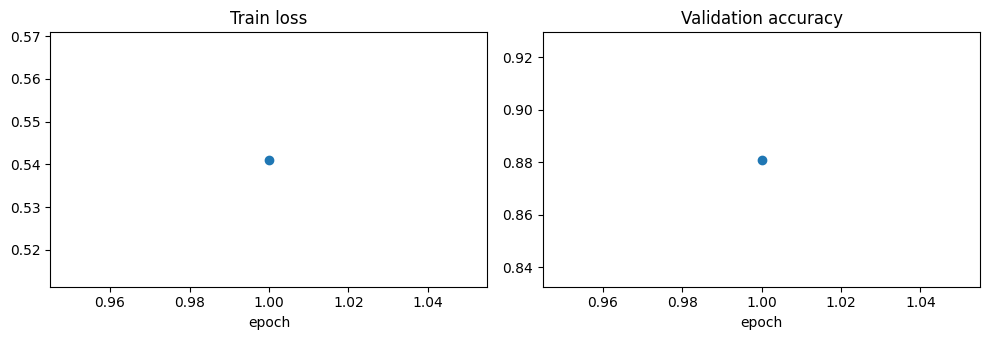

In [7]:
hist = pd.DataFrame(out["history"])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(hist["epoch"], hist["train_loss"], marker="o"); ax[0].set_title("Train loss"); ax[0].set_xlabel("epoch")
ax[1].plot(hist["epoch"], hist["val_accuracy"], marker="o"); ax[1].set_title("Validation accuracy"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

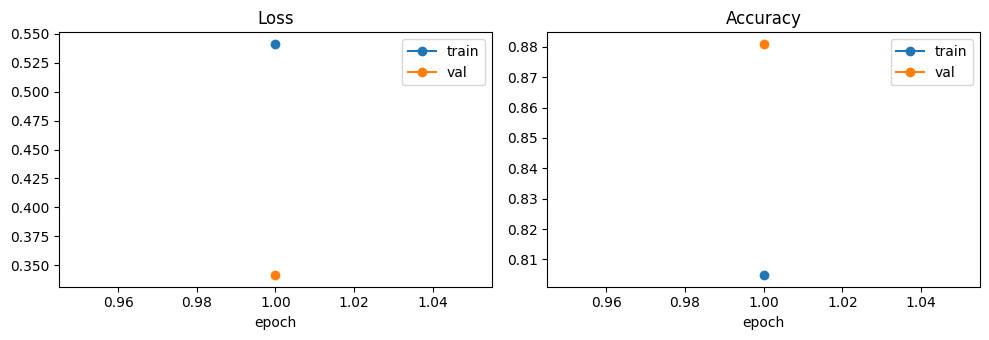

 epoch  train_loss  train_accuracy  val_loss  val_accuracy  epoch_time_s
     1      0.5411          0.8048    0.3416         0.881      220.8697
Epoch val tốt nhất: 1/1


In [8]:
# Đường cong đầy đủ (train/val loss + accuracy) đọc từ file history do src/train.py lưu
hp = out["metrics_path"].parent / "fine_tuning_history.csv"
if hp.exists():
    h = pd.read_csv(hp)
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
    ax[0].plot(h["epoch"], h["train_loss"], marker="o", label="train"); ax[0].plot(h["epoch"], h["val_loss"], marker="o", label="val")
    ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["epoch"], h["train_accuracy"], marker="o", label="train"); ax[1].plot(h["epoch"], h["val_accuracy"], marker="o", label="val")
    ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()
    print(h.round(4).to_string(index=False))
    best = h.loc[h["val_accuracy"].idxmax()]
    print(f"Epoch val tốt nhất: {int(best['epoch'])}/{len(h)}")
    if len(h) >= 2 and h['val_loss'].iloc[-1] > h['val_loss'].min():
        print("val_loss epoch cuối > val_loss thấp nhất -> dấu hiệu overfit: giữ epoch tốt nhất.")
else:
    print("Chưa có fine_tuning_history.csv -> chạy lại ô 'Chạy thí nghiệm' (đã được cập nhật để ghi history).")


### Training Monitoring → Decision (Fine-Tuning)
| Evidence (lần chạy chính thức) | Interpretation | Decision |
|---|---|---|
| 3 epoch, lr 2e-5, batch 32; val accuracy tốt nhất 0,9440 tại **epoch 2**; test 0,9422 (chênh +0,18 điểm %) | Chọn epoch theo validation không làm lệch test; epoch 3 không vượt epoch 2 → plateau hoặc bắt đầu overfit (chưa phân biệt được vì chưa có val loss) | Checkpoint = **epoch 2**; **giữ 3 epoch, không tăng epoch** (tạm thời) |
| Trước đây history chỉ có train loss + val accuracy và không được lưu | Không đủ để kết luận overfit | Đã cập nhật `src/train.py` ghi thêm `train_accuracy`, `val_loss` và lưu `fine_tuning_history.csv`; **cần chạy lại bản chính thức** để có đường cong thật |

**Quy tắc đọc đường cong:** `val_loss` tăng trong khi `train_loss` giảm ở epoch 3 → xác nhận giữ epoch 2; `val_loss` vẫn giảm → thử 4 epoch. Chi tiết: `docs/results/decision_log.md` mục 2.


## 6. Confusion matrix (xem nhanh)
Bản chính thức lưu vào `results/figures/` do `src/evaluate.py` (Trúc Chi) tạo.

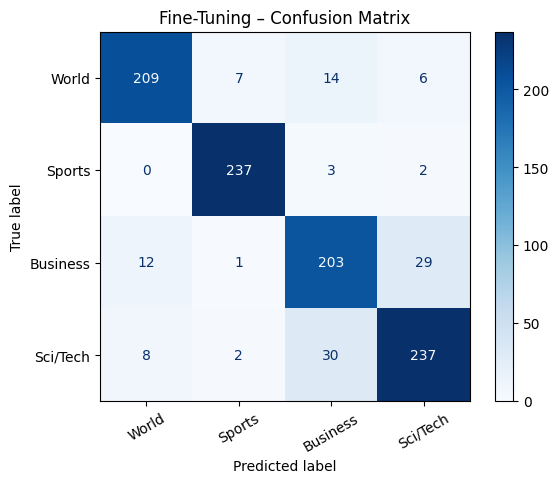

In [9]:
cm = confusion_matrix(out["y_true"], out["y_pred"])
ConfusionMatrixDisplay(cm, display_labels=LABEL_NAMES).plot(cmap="Blues", xticks_rotation=30)
plt.title("Fine-Tuning – Confusion Matrix"); plt.show()

## 7. Một vài mẫu dự đoán sai (tự tin cao nhất)

In [10]:
preds = pd.read_csv(out["predictions_path"])
wrong = preds[~preds["correct"]].sort_values("confidence", ascending=False)
print(f"Sai {len(wrong)}/{len(preds)} mẫu")
wrong[["text", "true_name", "pred_name", "confidence"]].head(10)

Sai 114/1000 mẫu


,text,true_name,pred_name,confidence
81,"At Last, Success on the Road for Lions The Det...",World,Sports,0.987649
897,"Cowboys Defeat Redskins 21-18 LANDOVER, Md. - ...",World,Sports,0.986346
9,Chavez rejects CD as opposition Venezuela 's P...,Business,World,0.985317
621,Indonesian diplomats asked to help improve RI ...,Business,World,0.983767
652,Stocks Climb on Drop in Consumer Prices NEW YO...,World,Business,0.978119
312,World briefs LONDON - A man wielding a machete...,Business,World,0.977720
556,Collingwood anchors England (AFP) AFP - Paul C...,World,Sports,0.973084
105,Thailand Shows No Easy War Against Wildlife Cr...,Sci/Tech,World,0.971164
493,Microsoft Launches New Media Center PC Microso...,Business,Sci/Tech,0.970229
816,Stocks Drop After Greenspan Testimony NEW YORK...,World,Business,0.968897


## 8. Thử dự đoán một câu

In [11]:
samples = ["Manchester United won the match 3-1.",
           "Apple unveils a new chip for its laptops.",
           "Stocks fell as oil prices surged on Tuesday."]
names, confs = ft.predict_texts(out["model"], out["tokenizer"], samples, max_len=64)
for s, n, c in zip(samples, names, confs):
    print(f"{n:9s} ({c:.2f})  {s}")

Sports    (0.97)  Manchester United won the match 3-1.
Sci/Tech  (0.96)  Apple unveils a new chip for its laptops.
Business  (0.97)  Stocks fell as oil prices surged on Tuesday.
